<a href="https://colab.research.google.com/github/Manjitha-MK/Flood-prediction/blob/main/phase2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

from google.colab import files

uploaded = files.upload()


Saving data_finish.csv to data_finish.csv


In [2]:

import pandas as pd

df = pd.read_csv("data_finish.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (6308, 15)


,date,Tn,Tx,Tavg,RH_avg,RR,ss,ff_x,ddd_x,ff_avg,ddd_car,station_id,station_name,region_name,flood
0,2016-01-01,26.0,34.8,28.6,81.0,NaN,5.8,5.0,280.0,2.0,S,96733,Stasiun Klimatologi Banten,Jakarta Selatan,0
1,2016-01-02,25.6,33.2,27.0,88.0,1.6,8.7,4.0,290.0,2.0,W,96733,Stasiun Klimatologi Banten,Jakarta Selatan,1
2,2016-01-03,24.4,34.9,28.1,80.0,33.8,5.4,4.0,280.0,2.0,SW,96733,Stasiun Klimatologi Banten,Jakarta Selatan,1
3,2016-01-04,24.8,33.6,29.2,81.0,NaN,6.6,3.0,200.0,1.0,S,96733,Stasiun Klimatologi Banten,Jakarta Selatan,0
4,2016-01-05,25.8,33.6,26.7,91.0,NaN,3.2,3.0,180.0,1.0,S,96733,Stasiun Klimatologi Banten,Jakarta Selatan,0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['date', 'Tn', 'Tx', 'Tavg', 'RH_avg', 'RR', 'ss', 'ff_x', 'ddd_x', 'ff_avg', 'ddd_car', 'station_id', 'station_name', 'region_name', 'flood']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6308 entries, 0 to 6307
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          6308 non-null   object 
 1   Tn            5996 non-null   float64
 2   Tx            6095 non-null   float64
 3   Tavg          6262 non-null   float64
 4   RH_avg        6256 non-null   float64
 5   RR            3993 non-null   float64
 6   ss            5049 non-null   float64
 7   ff_x          6286 non-null   float64
 8   ddd_x         6286 non-null   float64
 9   ff_avg        6215 non-null   float64
 10  ddd_car       6207 non-null   object 
 11  station_id    6308 non-null   int64  
 12  station_name  6308 non-null   object 
 13  region_name   6308 non-null   object 
 14  flood         6308 no

In [4]:
print("Missing values in each column:")
print(df.isnull().sum())


Missing values in each column:
date               0
Tn               312
Tx               213
Tavg              46
RH_avg            52
RR              2315
ss              1259
ff_x              22
ddd_x             22
ff_avg            93
ddd_car          101
station_id         0
station_name       0
region_name        0
flood              0
dtype: int64


In [5]:
print("Flood class counts:")
print(df["flood"].value_counts())

print("\nFlood class percentages:")
print(df["flood"].value_counts(normalize=True) * 100)

Flood class counts:
flood
0    5832
1     476
Name: count, dtype: int64

Flood class percentages:
flood
0    92.454027
1     7.545973
Name: proportion, dtype: float64


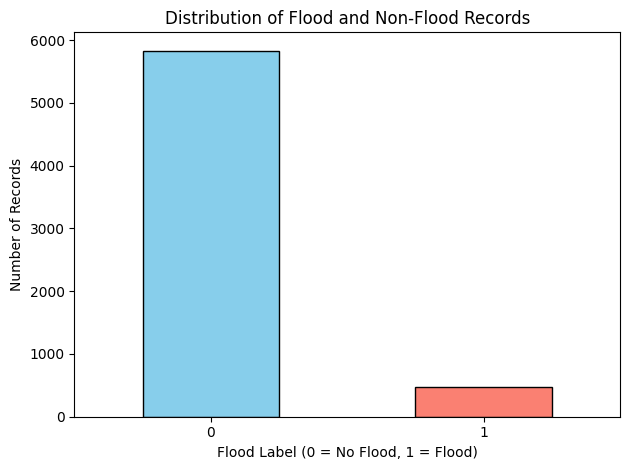

In [6]:
import matplotlib.pyplot as plt

df["flood"].value_counts().sort_index().plot(
    kind="bar",
    color=["skyblue", "salmon"],
    edgecolor="black"
)

plt.title("Distribution of Flood and Non-Flood Records")
plt.xlabel("Flood Label (0 = No Flood, 1 = Flood)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
# Separate the target
y = df["flood"]

# Select input features
X = df.drop(
    columns=["date", "flood", "station_name", "region_name"]
)

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Feature dataset shape: (6308, 11)
Target dataset shape: (6308,)

Input features:
['Tn', 'Tx', 'Tavg', 'RH_avg', 'RR', 'ss', 'ff_x', 'ddd_x', 'ff_avg', 'ddd_car', 'station_id']


In [8]:
# Convert the date column to datetime format
df["date"] = pd.to_datetime(df["date"])

# Training data: 2016–2019
train_mask = df["date"].dt.year <= 2019

# Testing data: 2020
test_mask = df["date"].dt.year == 2020

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining flood counts:")
print(y_train.value_counts())

print("\nTesting flood counts:")
print(y_test.value_counts())

Training records: 5249
Testing records: 1059

Training flood counts:
flood
0    4878
1     371
Name: count, dtype: int64

Testing flood counts:
flood
0    954
1    105
Name: count, dtype: int64


In [9]:
# Identify numerical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Station ID is an identifier, not a measurement
if "station_id" in numeric_features:
    numeric_features.remove("station_id")
    categorical_features.append("station_id")

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['Tn', 'Tx', 'Tavg', 'RH_avg', 'RR', 'ss', 'ff_x', 'ddd_x', 'ff_avg']

Categorical features:
['ddd_car', 'station_id']


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Prepare numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")


Preprocessing pipeline created successfully!


In [11]:
from sklearn.linear_model import LogisticRegression

# Create the complete machine learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [12]:
# Predict flood labels for the test data
y_pred = model.predict(X_test)

print("First 20 actual flood labels:")
print(y_test.head(20).tolist())

print("\nFirst 20 predicted flood labels:")
print(y_pred[:20].tolist())


First 20 actual flood labels:
[1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0]

First 20 predicted flood labels:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1]


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Logistic Regression Results")
print("----------------------------")
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall:    {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score:  {f1:.4f} ({f1 * 100:.2f}%)")


Logistic Regression Results
----------------------------
Accuracy:  0.7790 (77.90%)
Precision: 0.2753 (27.53%)
Recall:    0.7524 (75.24%)
F1-score:  0.4031 (40.31%)


Confusion Matrix:
[[746 208]
 [ 26  79]]


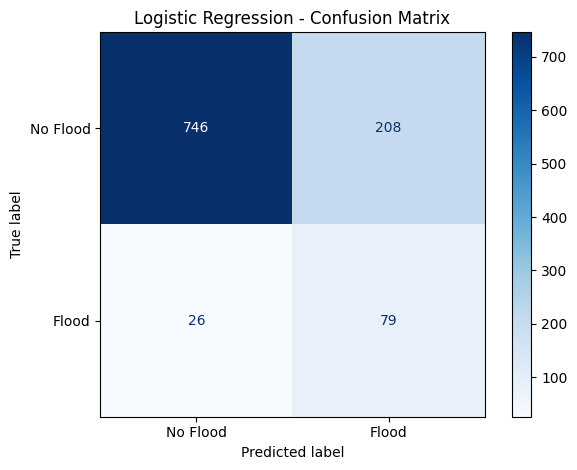

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Flood", "Flood"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [15]:
from sklearn.dummy import DummyClassifier

# Create a simple baseline that always predicts the majority class
majority_model = DummyClassifier(strategy="most_frequent")

# Fit using training data only
majority_model.fit(X_train, y_train)

# Predict on the same test records as Logistic Regression
y_majority_pred = majority_model.predict(X_test)

print("Majority-class baseline created successfully!")


Majority-class baseline created successfully!


In [16]:
print("Majority-Class Baseline Results")
print("--------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_majority_pred) * 100:.2f}%")
print(f"Precision: {precision_score(y_test, y_majority_pred, zero_division=0) * 100:.2f}%")
print(f"Recall:    {recall_score(y_test, y_majority_pred, zero_division=0) * 100:.2f}%")
print(f"F1-score:  {f1_score(y_test, y_majority_pred, zero_division=0) * 100:.2f}%")


Majority-Class Baseline Results
--------------------------------
Accuracy:  90.08%
Precision: 0.00%
Recall:    0.00%
F1-score:  0.00%


                 Model  Accuracy  Precision  Recall  F1-score
0    Majority Baseline    0.9008     0.0000  0.0000    0.0000
1  Logistic Regression    0.7790     0.2753  0.7524    0.4031


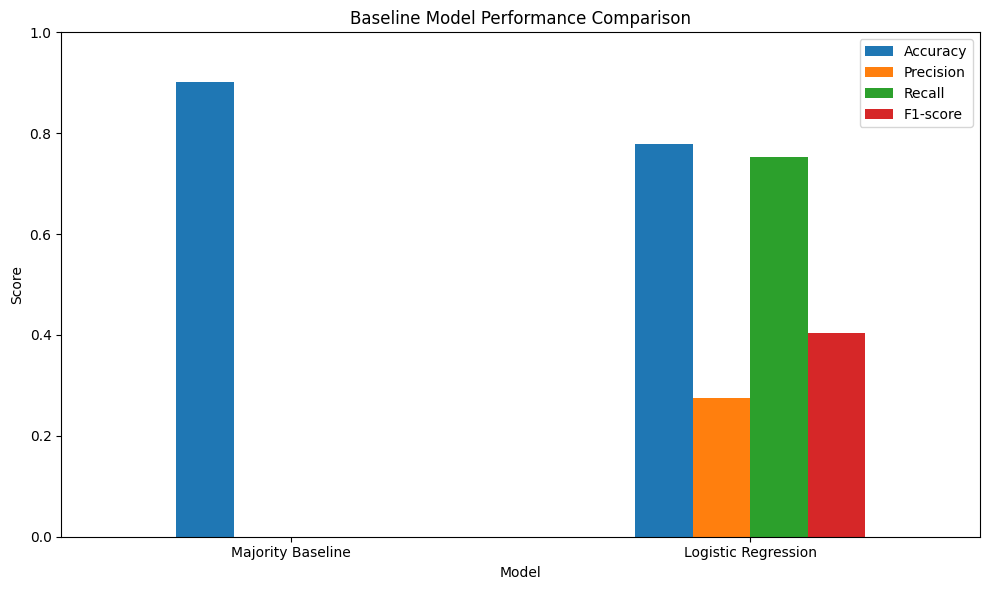

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Model": ["Majority Baseline", "Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_majority_pred),
        accuracy_score(y_test, y_pred)
    ],
    "Precision": [
        precision_score(y_test, y_majority_pred, zero_division=0),
        precision_score(y_test, y_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_majority_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_majority_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

print(comparison.round(4))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


In [18]:
paper_results = pd.DataFrame({
    "Model": [
        "Logistic Regression (Paper)",
        "Naive Bayes (Paper)",
        "KNN (Paper)",
        "Decision Tree (Paper)",
        "Random Forest (Paper)"
    ],
    "Accuracy": [79.513, 77.256, 95.130, 91.448, 95.902],
    "Precision": [78.167, 76.436, 91.767, 90.311, 94.482],
    "Recall": [81.969, 78.884, 99.169, 92.882, 97.508],
    "ROC-AUC": [79.510, 77.254, 95.125, 91.447, 95.900]
})

print(paper_results.to_string(index=False))


                      Model  Accuracy  Precision  Recall  ROC-AUC
Logistic Regression (Paper)    79.513     78.167  81.969   79.510
        Naive Bayes (Paper)    77.256     76.436  78.884   77.254
                KNN (Paper)    95.130     91.767  99.169   95.125
      Decision Tree (Paper)    91.448     90.311  92.882   91.447
      Random Forest (Paper)    95.902     94.482  97.508   95.900


                      Model  Accuracy  Precision  Recall
          Majority Baseline     90.08       0.00    0.00
 Logistic Regression (Ours)     77.90      27.53   75.24
Logistic Regression (Paper)     79.51      78.17   81.97
        Naive Bayes (Paper)     77.26      76.44   78.88
                KNN (Paper)     95.13      91.77   99.17
      Decision Tree (Paper)     91.45      90.31   92.88
      Random Forest (Paper)     95.90      94.48   97.51


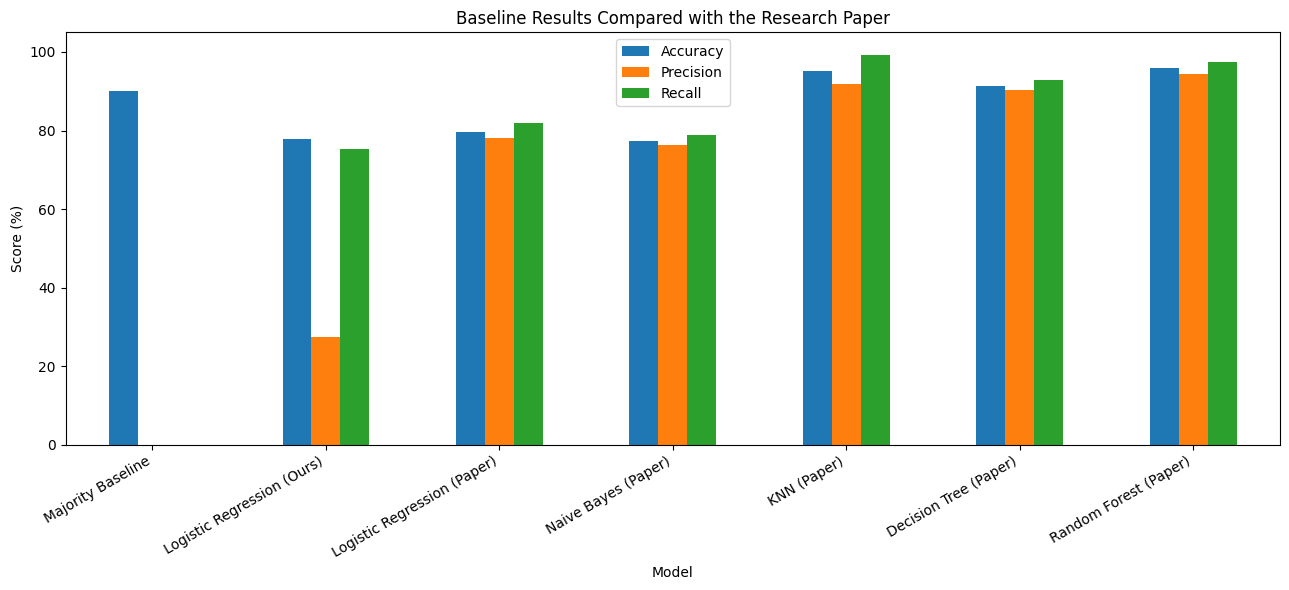

In [19]:
# Create results for our two baseline models
our_results = pd.DataFrame({
    "Model": ["Majority Baseline", "Logistic Regression (Ours)"],
    "Accuracy": [
        accuracy_score(y_test, y_majority_pred) * 100,
        accuracy_score(y_test, y_pred) * 100
    ],
    "Precision": [
        precision_score(y_test, y_majority_pred, zero_division=0) * 100,
        precision_score(y_test, y_pred, zero_division=0) * 100
    ],
    "Recall": [
        recall_score(y_test, y_majority_pred, zero_division=0) * 100,
        recall_score(y_test, y_pred, zero_division=0) * 100
    ]
})

# Select the same metrics from the paper
paper_plot = paper_results[
    ["Model", "Accuracy", "Precision", "Recall"]
].copy()

# Combine both sets of results
all_results = pd.concat(
    [our_results, paper_plot],
    ignore_index=True
)

print(all_results.round(2).to_string(index=False))

# Plot accuracy, precision and recall
all_results.set_index("Model").plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Baseline Results Compared with the Research Paper")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.ylim(0, 105)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()


In [20]:
# Save the results table
all_results.to_csv("phase2_model_comparison.csv", index=False)

# Save the flood distribution plot
plt.figure(figsize=(7, 5))
df["flood"].value_counts().sort_index().plot(
    kind="bar",
    color=["skyblue", "salmon"],
    edgecolor="black"
)
plt.title("Distribution of Flood and Non-Flood Records")
plt.xlabel("Flood Label (0 = No Flood, 1 = Flood)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figure1_flood_distribution.png", dpi=300, bbox_inches="tight")
plt.close()

# Save the confusion matrix plot
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Flood", "Flood"]
)
cm_display.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig("figure2_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.close()

# Save the baseline comparison plot
comparison.set_index("Model").plot(kind="bar", figsize=(10, 6))
plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figure3_baseline_comparison.png", dpi=300, bbox_inches="tight")
plt.close()

# Save the paper comparison plot
all_results.set_index("Model").plot(kind="bar", figsize=(13, 6))
plt.title("Baseline Results Compared with the Research Paper")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.ylim(0, 105)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figure4_paper_comparison.png", dpi=300, bbox_inches="tight")
plt.close()

print("All Phase 2 results and plots have been saved!")


All Phase 2 results and plots have been saved!


In [1]:
!git clone https://github.com/Manjitha-MK/Flood-prediction.git

Cloning into 'Flood-prediction'...
